<h1 style="text-align:center; font-family:'Times New Roman';">
Skin Cancer Classification and Explainability Using Deep Learning (2)
</h1>


This notebook focuses on the explainability of the previously trained ConvNeXt-Tiny and Swin-Tiny models.

It investigates how the models make their predictions using Explainable Artificial Intelligence (XAI) techniques, particularly Grad-CAM and masking analysis. These methods help visualize the image regions influencing model predictions and assess their contribution to the classification process.

**Recréer l'environnement :**

Je recrée donc l'environnement nécessaire pour poursuivre avec **xai**, en réutilisant le dataset nettoyé et le modèle ConvNeXt et Swin-Tiny sauvegardés. Je réexécute également certaines cellules de la partie Prétraitement des images pour restaurer les transformations et les DataLoaders, sans refaire le nettoyage des données.

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Je vérifie si un GPU est disponible pour accélérer l'entraînement.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Je récupère les chemins du dataset déjà nettoyé.
BASE_DIR = "/kaggle/input/datasets/aminaelmoubtahij/skin-cancer-clean"
# Je récupère les chemins du meilleur modèle de convexnet.
CONVNEXT_PATH = "/kaggle/input/models/aminaelmoubtahij/best-convnext-tiny/pytorch/default/1/best_convnext_tiny.pth"
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VALID_DIR = os.path.join(BASE_DIR, "valid")
TEST_DIR = os.path.join(BASE_DIR, "test")

IMG_SIZE = 224
BATCH_SIZE = 32

print("Device :", device)
print("Dataset disponible :", os.path.exists(TRAIN_DIR))
print("Modèle ConvNeXt disponible :", os.path.exists(CONVNEXT_PATH))

In [ ]:
# Valeurs de normalisation ImageNet utilisées avec les modèles pré-entraînés
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Transformations appliquées uniquement aux images d'entraînement
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Transformations sans augmentation pour validation et test
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

In [ ]:
# Chargement des trois ensembles avec leurs transformations respectives
train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    root=VALID_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)

assert train_dataset.class_to_idx == valid_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

**Restauration des 2 modèles**

In [ ]:
import torchvision.models as models
import torch.nn as nn
# Je définis le chemin du meilleur modèle Swin-Tiny.
SWIN_PATH = "/kaggle/input/models/aminaelmoubtahij/best-swin-tiny/pytorch/default/1/best_swin_tiny.pth"

# Je reconstruis Swin-Tiny et sa couche de classification.
model_swin = models.swin_t(weights=None)
model_swin.head = nn.Linear(model_swin.head.in_features, 2)

# Je charge les meilleurs poids de Swin-Tiny.
checkpoint_swin = torch.load(SWIN_PATH, map_location=device)
model_swin.load_state_dict(checkpoint_swin)

# Je prépare le modèle pour l'évaluation.
model_swin = model_swin.to(device).eval()

In [ ]:
# Je définis le chemin du meilleur modèle ConvNeXt-Tiny.
CONVNEXT_PATH = "/kaggle/input/models/aminaelmoubtahij/best-convnext-tiny/pytorch/default/1/best_convnext_tiny.pth"

# Je reconstruis ConvNeXt-Tiny et sa couche de classification.
model_convnext = models.convnext_tiny(weights=None)
model_convnext.classifier[2] = nn.Linear(
    model_convnext.classifier[2].in_features, 2
)

# Je charge les meilleurs poids.
checkpoint_convnext = torch.load(CONVNEXT_PATH, map_location=device)
model_convnext.load_state_dict(checkpoint_convnext["model_state_dict"])

# Je prépare le modèle pour l'évaluation.
model_convnext = model_convnext.to(device).eval()

**Expérience 1 — Visualisation et comparaison des explications**

**Installer et importer Grad-CAM**

In [6]:
!pip install -q grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from scipy.stats import wilcoxon

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

**Visualisation et comparaison des explications**

In [8]:
# Je récupère les vraies classes du jeu de test.
y_true = np.array(test_dataset.targets)

# Je calcule les prédictions des deux modèles.
def get_predictions(model):

    model.eval()
    logits_list = []

    test_loader_eval = torch.utils.data.DataLoader(
        test_dataset,
        batch_size=32,
        shuffle=False
    )

    with torch.no_grad():
        for images, _ in test_loader_eval:
            images = images.to(device)
            logits = model(images)
            logits_list.append(logits.cpu().numpy())

    return np.concatenate(logits_list)


logits_convnext = get_predictions(model_convnext)
logits_swin = get_predictions(model_swin)

# Je récupère les probabilités et les classes prédites.
prob_convnext = torch.softmax(
    torch.tensor(logits_convnext), dim=1
).numpy()

prob_swin = torch.softmax(
    torch.tensor(logits_swin), dim=1
).numpy()

pred_convnext = logits_convnext.argmax(axis=1)
pred_swin = logits_swin.argmax(axis=1)

print("Nombre d'images :", len(y_true))
print("Classes :", test_dataset.class_to_idx)
print("Prédictions des deux modèles récupérées.")

Nombre d'images : 999
Classes : {'benign': 0, 'malignant': 1}
Prédictions des deux modèles récupérées.


**Sélectionner les situations représentatives**

In [9]:
# Je récupère les indices des classes.
BENIGN = test_dataset.class_to_idx["benign"]
MALIGNANT = test_dataset.class_to_idx["malignant"]

# Je définis les groupes d'analyse.
groups = {
    "Bénin correctement classé": (
        (y_true == BENIGN) &
        (pred_convnext == BENIGN) &
        (pred_swin == BENIGN)
    ),

    "Malin correctement classé": (
        (y_true == MALIGNANT) &
        (pred_convnext == MALIGNANT) &
        (pred_swin == MALIGNANT)
    ),

    "Bénin mal classé": (
        (y_true == BENIGN) &
        (pred_convnext == MALIGNANT) &
        (pred_swin == MALIGNANT)
    ),

    "Malin mal classé": (
        (y_true == MALIGNANT) &
        (pred_convnext == BENIGN) &
        (pred_swin == BENIGN)
    ),

    "Désaccord entre les modèles": (
        pred_convnext != pred_swin
    )
}

# Je sélectionne deux images dans chaque groupe.
rng = np.random.default_rng(42)

selected_images = []

for group_name, condition in groups.items():

    candidates = np.where(condition)[0]
    number = min(2, len(candidates))

    chosen = rng.choice(
        candidates,
        size=number,
        replace=False
    )

    selected_images.extend([
        (int(index), group_name)
        for index in chosen
    ])

print("Nombre d'images sélectionnées :", len(selected_images))

for group_name, condition in groups.items():
    print(group_name, ":", int(condition.sum()), "images disponibles")

Nombre d'images sélectionnées : 10
Bénin correctement classé : 470 images disponibles
Malin correctement classé : 430 images disponibles
Bénin mal classé : 14 images disponibles
Malin mal classé : 49 images disponibles
Désaccord entre les modèles : 36 images disponibles


**Initialiser Grad-CAM pour les deux architectures**

In [10]:
# Adaptation des caractéristiques spatiales de Swin-Tiny.
def reshape_swin(tensor):
    return tensor.permute(0, 3, 1, 2)


target_layer_convnext = model_convnext.features[-1]

target_layer_swin = model_swin.features[-1][-1].norm1

print("Couches Grad-CAM définies pour les deux modèles.")

Couches Grad-CAM définies pour les deux modèles.


**Générer et visualiser les cartes Grad-CAM**

In [11]:
# Je restaure les prédictions de Swin à partir des logits déjà calculés.
pred_swin = logits_swin.argmax(axis=1)

print("Type :", type(pred_swin))
print("Dimensions :", pred_swin.shape)

Type : <class 'numpy.ndarray'>
Dimensions : (999,)


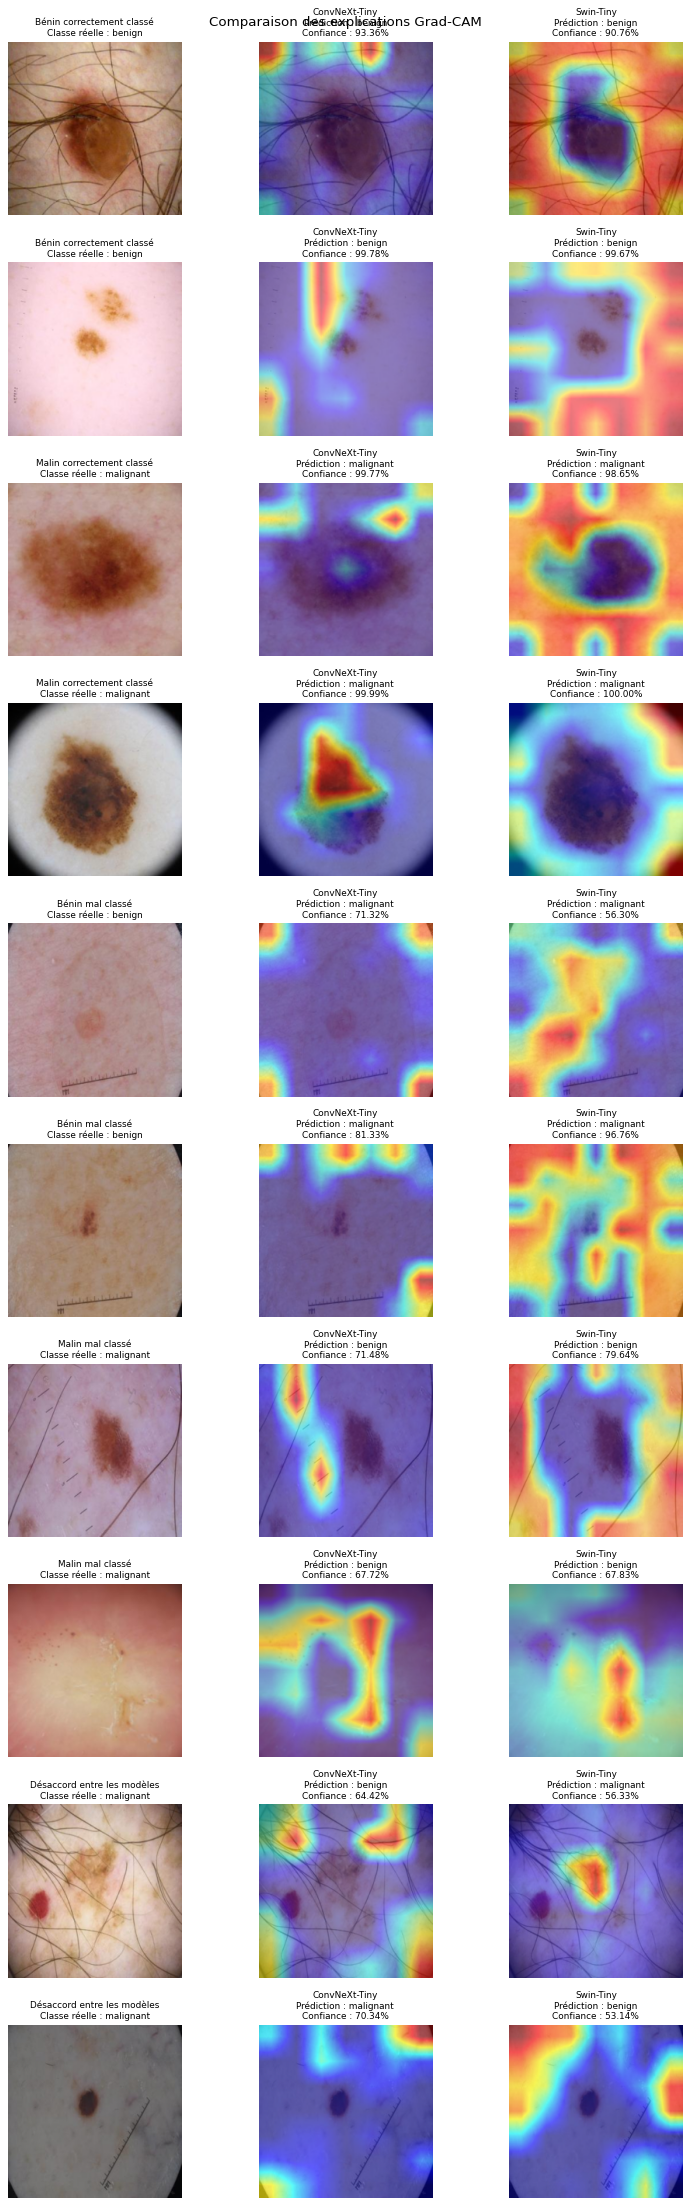

In [25]:
# Je prépare les deux modèles Grad-CAM.
model_convnext.eval()
model_swin.eval()

fig, axes = plt.subplots(
    len(selected_images), 3,
    figsize=(10, 2.8 * len(selected_images)),
    dpi=80
)

if len(selected_images) == 1:
    axes = axes.reshape(1, 3)

with GradCAM(
    model=model_convnext,
    target_layers=[target_layer_convnext]
) as cam_convnext, GradCAM(
    model=model_swin,
    target_layers=[target_layer_swin],
    reshape_transform=reshape_swin
) as cam_swin:

    for row, (idx, group_name) in enumerate(selected_images):

        image, true_label = test_dataset[idx]
        input_tensor = image.unsqueeze(0).to(device)

        # Je reconstruis l'image originale.
        original_image = (
            image.cpu().permute(1, 2, 0).numpy()
            * np.array(STD)
            + np.array(MEAN)
        )

        original_image = np.clip(
            original_image, 0, 1
        ).astype(np.float32)

        # Prédictions individuelles.
        pred_cnx = int(pred_convnext[idx])
        pred_sw = int(pred_swin[idx])

        # Grad-CAM de ConvNeXt.
        cam_cnx = cam_convnext(
            input_tensor=input_tensor,
            targets=[ClassifierOutputTarget(pred_cnx)]
        )[0]

        # Grad-CAM de Swin.
        cam_sw = cam_swin(
            input_tensor=input_tensor,
            targets=[ClassifierOutputTarget(pred_sw)]
        )[0]

        # Superpositions.
        overlay_cnx = show_cam_on_image(
            original_image,
            cam_cnx,
            use_rgb=True,
            image_weight=0.55
        )

        overlay_swin = show_cam_on_image(
            original_image,
            cam_sw,
            use_rgb=True,
            image_weight=0.55
        )

        true_name = test_dataset.classes[true_label]
        pred_cnx_name = test_dataset.classes[pred_cnx]
        pred_swin_name = test_dataset.classes[pred_sw]

        # Affichage.
        axes[row, 0].imshow(original_image)
        axes[row, 0].set_title(
            f"{group_name}\n"
            f"Classe réelle : {true_name}",
            fontsize=8
        )

        axes[row, 1].imshow(overlay_cnx)
        axes[row, 1].set_title(
            f"ConvNeXt-Tiny\nPrédiction : {pred_cnx_name}\n"
            f"Confiance : {prob_convnext[idx, pred_cnx]:.2%}",
            fontsize=8
        )

        axes[row, 2].imshow(overlay_swin)
        axes[row, 2].set_title(
            f"Swin-Tiny\nPrédiction : {pred_swin_name}\n"
            f"Confiance : {prob_swin[idx, pred_sw]:.2%}",
            fontsize=8
        )

        for ax in axes[row]:
            ax.axis("off")

plt.suptitle(
    "Comparaison des explications Grad-CAM",
    fontsize=12
)

plt.tight_layout()
plt.show()
plt.close(fig)


**Expérience 2 — Analyse explicative des erreurs**

**Sélectionner les erreurs des deux modèles**

In [13]:
# Je récupère les indices des images mal classées
# indépendamment pour chaque modèle.

error_indices = {
    "ConvNeXt-Tiny": np.where(
        pred_convnext != y_true
    )[0],

    "Swin-Tiny": np.where(
        pred_swin != y_true
    )[0]
}

# Je sélectionne des erreurs représentatives
# pour chaque classe réelle.

rng_error = np.random.default_rng(2026)

error_samples = []

for model_name, indices in error_indices.items():

    predictions = (
        pred_convnext
        if model_name == "ConvNeXt-Tiny"
        else pred_swin
    )

    for true_class in range(len(test_dataset.classes)):

        candidates = indices[
            y_true[indices] == true_class
        ]

        number = min(4, len(candidates))

        if number == 0:
            continue

        chosen = rng_error.choice(
            candidates,
            size=number,
            replace=False
        )

        for idx in chosen:

            error_samples.append({
                "Modèle": model_name,
                "Image": int(idx),
                "Classe réelle": int(y_true[idx]),
                "Classe prédite": int(predictions[idx])
            })

error_samples_df = pd.DataFrame(error_samples)

display(error_samples_df)

print("\nNombre d'erreurs sélectionnées :",
      len(error_samples_df))

print("\nRépartition des erreurs :")

display(
    error_samples_df.groupby(
        ["Modèle", "Classe réelle", "Classe prédite"]
    ).size().rename("Nombre d'images")
)


,Modèle,Image,Classe réelle,Classe prédite
0,ConvNeXt-Tiny,0,0,1
1,ConvNeXt-Tiny,400,0,1
2,ConvNeXt-Tiny,366,0,1
3,ConvNeXt-Tiny,42,0,1
4,ConvNeXt-Tiny,535,1,0
5,ConvNeXt-Tiny,962,1,0
6,ConvNeXt-Tiny,996,1,0
7,ConvNeXt-Tiny,981,1,0
8,Swin-Tiny,50,0,1
9,Swin-Tiny,366,0,1



Nombre d'erreurs sélectionnées : 16

Répartition des erreurs :


Modèle         Classe réelle  Classe prédite
ConvNeXt-Tiny  0              1                 4
               1              0                 4
Swin-Tiny      0              1                 4
               1              0                 4
Name: Nombre d'images, dtype: int64

**Comparer les explications de la classe prédite et de la vraie classe**


Analyse des erreurs : ConvNeXt-Tiny


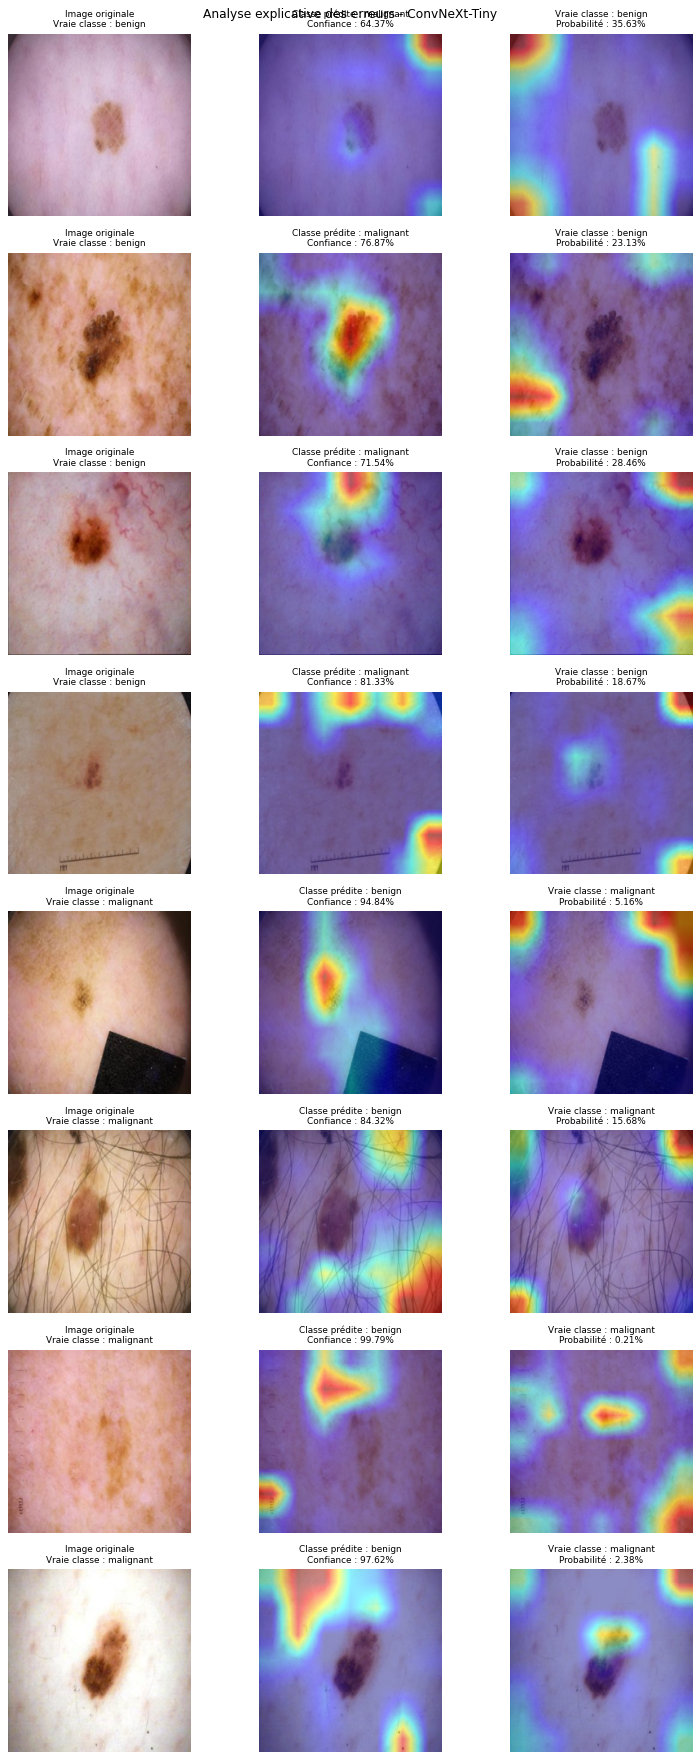


Analyse des erreurs : Swin-Tiny


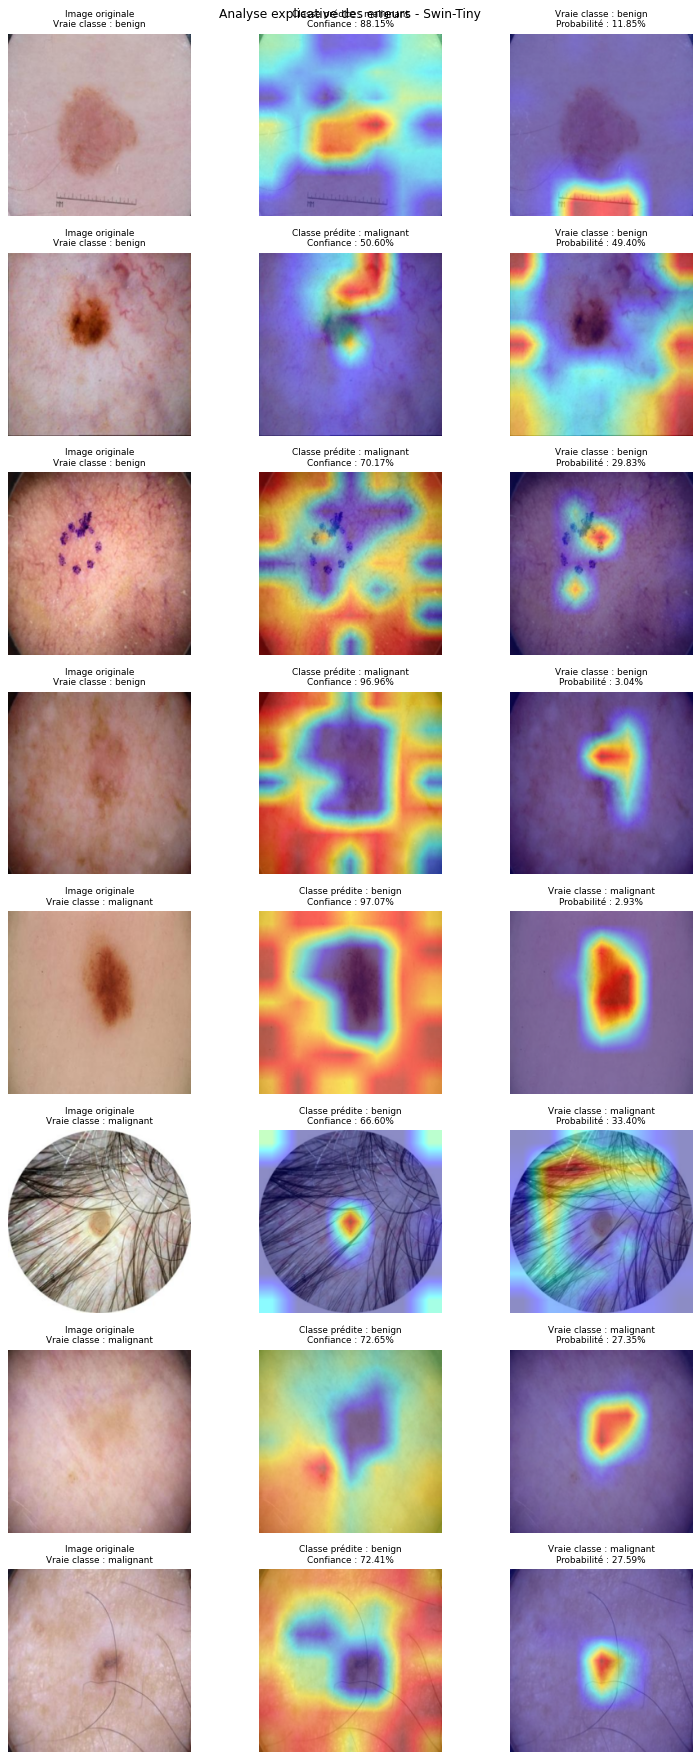

In [26]:
# Je prépare les informations déjà disponibles pour les deux modèles.

error_xai_models = {
    "ConvNeXt-Tiny": {
        "model": model_convnext,
        "target_layer": target_layer_convnext,
        "reshape": None,
        "probabilities": prob_convnext
    },

    "Swin-Tiny": {
        "model": model_swin,
        "target_layer": target_layer_swin,
        "reshape": reshape_swin,
        "probabilities": prob_swin
    }
}

# Je génère deux cartes Grad-CAM pour chaque erreur.

for model_name, config in error_xai_models.items():

    model = config["model"]
    model.eval()

    model_errors = error_samples_df[
        error_samples_df["Modèle"] == model_name
    ]

    if len(model_errors) == 0:
        print(f"Aucune erreur sélectionnée pour {model_name}.")
        continue

    cam_args = {
        "model": model,
        "target_layers": [config["target_layer"]]
    }

    if config["reshape"] is not None:
        cam_args["reshape_transform"] = config["reshape"]

    print(f"\nAnalyse des erreurs : {model_name}")

    with GradCAM(**cam_args) as cam:

        fig, axes = plt.subplots(
            len(model_errors),
            3,
            figsize=(10, 2.8 * len(model_errors)),
            dpi=80
        )

        if len(model_errors) == 1:
            axes = axes.reshape(1, 3)

        for row, (_, sample) in enumerate(
            model_errors.iterrows()
        ):

            idx = int(sample["Image"])

            true_class = int(sample["Classe réelle"])
            predicted_class = int(sample["Classe prédite"])

            # Je récupère l'image.
            image, _ = test_dataset[idx]

            input_tensor = image.unsqueeze(0).to(device)

            # Je reconstruis l'image originale.
            original_image = (
                image.cpu().permute(1, 2, 0).numpy()
                * np.array(STD)
                + np.array(MEAN)
            )

            original_image = np.clip(
                original_image, 0, 1
            ).astype(np.float32)

            # Grad-CAM ciblant la classe prédite.
            cam_predicted = cam(
                input_tensor=input_tensor,
                targets=[
                    ClassifierOutputTarget(predicted_class)
                ]
            )[0]

            # Grad-CAM ciblant la vraie classe.
            cam_true = cam(
                input_tensor=input_tensor,
                targets=[
                    ClassifierOutputTarget(true_class)
                ]
            )[0]

            # Superposition des deux cartes.
            overlay_predicted = show_cam_on_image(
                original_image,
                cam_predicted,
                use_rgb=True,
                image_weight=0.55
            )

            overlay_true = show_cam_on_image(
                original_image,
                cam_true,
                use_rgb=True,
                image_weight=0.55
            )

            true_name = test_dataset.classes[true_class]
            predicted_name = test_dataset.classes[predicted_class]

            confidence_predicted = config["probabilities"][
                idx, predicted_class
            ]

            confidence_true = config["probabilities"][
                idx, true_class
            ]

            # Image originale.
            axes[row, 0].imshow(original_image)
            axes[row, 0].set_title(
                f"Image originale\nVraie classe : {true_name}",
                fontsize=8
            )

            # Explication de la classe prédite.
            axes[row, 1].imshow(overlay_predicted)
            axes[row, 1].set_title(
                f"Classe prédite : {predicted_name}\n"
                f"Confiance : {confidence_predicted:.2%}",
                fontsize=8
            )

            # Explication de la vraie classe.
            axes[row, 2].imshow(overlay_true)
            axes[row, 2].set_title(
                f"Vraie classe : {true_name}\n"
                f"Probabilité : {confidence_true:.2%}",
                fontsize=8
            )

            for ax in axes[row]:
                ax.axis("off")

        plt.suptitle(
            f"Analyse explicative des erreurs - {model_name}",
            fontsize=11
        )

        plt.tight_layout()
        plt.show()
        plt.close(fig)


**Analyse quantitative des erreurs et des confiances**

In [15]:
# Je construis un tableau détaillé des erreurs.

error_analysis = []

for model_name, config in error_xai_models.items():

    probabilities = config["probabilities"]

    model_errors = error_samples_df[
        error_samples_df["Modèle"] == model_name
    ]

    for _, sample in model_errors.iterrows():

        idx = int(sample["Image"])

        true_class = int(sample["Classe réelle"])
        predicted_class = int(sample["Classe prédite"])

        confidence_predicted = float(
            probabilities[idx, predicted_class]
        )

        confidence_true = float(
            probabilities[idx, true_class]
        )

        error_analysis.append({

            "Modèle": model_name,

            "Image": idx,

            "Classe réelle":
                test_dataset.classes[true_class],

            "Classe prédite":
                test_dataset.classes[predicted_class],

            "Confiance prédiction":
                confidence_predicted,

            "Probabilité vraie classe":
                confidence_true,

            "Écart de confiance":
                confidence_predicted - confidence_true
        })

error_analysis_df = pd.DataFrame(error_analysis)

print("Analyse détaillée des erreurs :")

display(error_analysis_df.round(4))

print("\nRésumé par modèle et type d'erreur :")

error_summary = (
    error_analysis_df
    .groupby(["Modèle", "Classe réelle", "Classe prédite"])
    .agg(
        Nombre_erreurs=("Image", "count"),
        Confiance_moyenne=("Confiance prédiction", "mean"),
        Probabilite_vraie_moyenne=(
            "Probabilité vraie classe", "mean"
        ),
        Ecart_moyen=("Écart de confiance", "mean")
    )
    .round(4)
)

display(error_summary)


Analyse détaillée des erreurs :


,Modèle,Image,Classe réelle,Classe prédite,Confiance prédiction,Probabilité vraie classe,Écart de confiance
0,ConvNeXt-Tiny,0,benign,malignant,0.6437,0.3563,0.2875
1,ConvNeXt-Tiny,400,benign,malignant,0.7687,0.2313,0.5375
2,ConvNeXt-Tiny,366,benign,malignant,0.7154,0.2846,0.4307
3,ConvNeXt-Tiny,42,benign,malignant,0.8133,0.1867,0.6266
4,ConvNeXt-Tiny,535,malignant,benign,0.9484,0.0516,0.8968
5,ConvNeXt-Tiny,962,malignant,benign,0.8432,0.1568,0.6863
6,ConvNeXt-Tiny,996,malignant,benign,0.9979,0.0021,0.9958
7,ConvNeXt-Tiny,981,malignant,benign,0.9762,0.0238,0.9525
8,Swin-Tiny,50,benign,malignant,0.8815,0.1185,0.7630
9,Swin-Tiny,366,benign,malignant,0.5060,0.4940,0.0120



Résumé par modèle et type d'erreur :


Nombre_erreurs  Confiance_moyenne  \
Modèle        Classe réelle Classe prédite                                      
ConvNeXt-Tiny benign        malignant                    4             0.7353   
              malignant     benign                       4             0.9414   
Swin-Tiny     benign        malignant                    4             0.7647   
              malignant     benign                       4             0.7718   

                                            Probabilite_vraie_moyenne  \
Modèle        Classe réelle Classe prédite                              
ConvNeXt-Tiny benign        malignant                          0.2647   
              malignant     benign                             0.0586   
Swin-Tiny     benign        malignant                          0.2353   
              malignant     benign                             0.2282   

                                            Ecart_moyen  
Modèle        Classe réelle Classe prédite               
ConvNeXt-Tiny benign        malignant            0.4706  
              malignant     benign               0.8828  
Swin-Tiny     benign        malignant            0.5294  
              malignant     benign               0.5436

**Experience 3: Vérifier l'influence des régions mises en évidence**

on utilise les mêmes cinq situations que dans l'expérience 1, mais avec jusqu'à 20 images par groupe.

In [18]:
rng = np.random.default_rng(123)

quantitative_images = []

for group_name, condition in groups.items():

    candidates = np.where(condition)[0]
    number = min(20, len(candidates))

    chosen = rng.choice(
        candidates,
        size=number,
        replace=False
    )

    quantitative_images.extend([
        (int(index), group_name)
        for index in chosen
    ])

print(
    "Nombre total d'images pour l'expérience :",
    len(quantitative_images)
)

for group_name, condition in groups.items():
    selected_count = sum(
        name == group_name
        for _, name in quantitative_images
    )

    print(group_name, ":", selected_count)

Nombre total d'images pour l'expérience : 94
Bénin correctement classé : 20
Malin correctement classé : 20
Bénin mal classé : 14
Malin mal classé : 20
Désaccord entre les modèles : 20


**fonctions de masquage et de calcul**

In [19]:
def calculate_margin(model, input_tensor, predicted_class):

    with torch.no_grad():
        logits = model(input_tensor)[0]

    other_class = 1 - predicted_class

    margin = (
        logits[predicted_class] - logits[other_class]
    ).item()

    new_prediction = logits.argmax().item()

    return margin, new_prediction


def create_cam_mask(cam, method, ratio=0.20, rng=None):

    flat_cam = cam.flatten()
    number_pixels = int(ratio * len(flat_cam))

    if method == "hot":
        indices = np.argsort(flat_cam)[-number_pixels:]

    elif method == "cold":
        indices = np.argsort(flat_cam)[:number_pixels]

    elif method == "random":
        indices = rng.choice(
            len(flat_cam),
            size=number_pixels,
            replace=False
        )

    else:
        raise ValueError("Méthode de masquage inconnue.")

    mask = np.zeros(len(flat_cam), dtype=bool)
    mask[indices] = True

    return mask.reshape(cam.shape)


def apply_mask(input_tensor, mask):

    mask_tensor = torch.as_tensor(
        mask,
        dtype=torch.bool,
        device=device
    )

    masked_image = input_tensor.clone()

    masked_image[0, :, mask_tensor] = 0

    return masked_image

**calculer Grad-CAM pour chaque modèle et utiliser sa propre classe prédite comme cible**

In [20]:
models_to_test = {
    "ConvNeXt": {
        "model": model_convnext,
        "target_layer": target_layer_convnext,
        "reshape": None,
        "predictions": pred_convnext
    },

    "Swin": {
        "model": model_swin,
        "target_layer": target_layer_swin,
        "reshape": reshape_swin,
        "predictions": pred_swin
    }
}

results = []

random_repeats = 5
rng = np.random.default_rng(42)

for model_name, config in models_to_test.items():

    model = config["model"]
    predictions = config["predictions"]

    print("Analyse :", model_name)

    with GradCAM(
        model=model,
        target_layers=[config["target_layer"]],
        reshape_transform=config["reshape"]
    ) as cam_method:

        for index, group_name in quantitative_images:

            image, true_label = test_dataset[index]
            input_tensor = image.unsqueeze(0).to(device)

            predicted_class = int(predictions[index])

            # Marge initiale.
            original_margin, _ = calculate_margin(
                model,
                input_tensor,
                predicted_class
            )

            # Carte Grad-CAM de la classe prédite.
            cam = cam_method(
                input_tensor=input_tensor,
                targets=[
                    ClassifierOutputTarget(predicted_class)
                ]
            )[0]

            # Trois conditions de masquage.
            masks = {
                "hot": [
                    create_cam_mask(cam, "hot", rng=rng)
                ],

                "cold": [
                    create_cam_mask(cam, "cold", rng=rng)
                ],

                "random": [
                    create_cam_mask(cam, "random", rng=rng)
                    for _ in range(random_repeats)
                ]
            }

            for condition_name, condition_masks in masks.items():

                margins = []
                predictions_after = []

                for mask in condition_masks:

                    masked_image = apply_mask(
                        input_tensor,
                        mask
                    )

                    margin, new_prediction = calculate_margin(
                        model,
                        masked_image,
                        predicted_class
                    )

                    margins.append(margin)
                    predictions_after.append(
                        new_prediction != predicted_class
                    )

                # Moyenne des cinq essais pour le contrôle aléatoire.
                mean_masked_margin = np.mean(margins)
                mean_prediction_change = np.mean(
                    predictions_after
                )

                results.append({
                    "Image": index,
                    "Groupe": group_name,
                    "Classe réelle": test_dataset.classes[true_label],
                    "Modèle": model_name,
                    "Condition": condition_name,
                    "Marge originale": original_margin,
                    "Marge masquée": mean_masked_margin,
                    "Baisse de marge": (
                        original_margin - mean_masked_margin
                    ),
                    "Changement de prédiction": mean_prediction_change
                })

    print("Terminé :", model_name)

results_df = pd.DataFrame(results)

print("\nExpérience de masquage terminée.")
print("Nombre de mesures :", len(results_df))

Analyse : ConvNeXt
Terminé : ConvNeXt
Analyse : Swin
Terminé : Swin

Expérience de masquage terminée.
Nombre de mesures : 564


**Analyser les résultats**

In [21]:
summary_results = (
    results_df
    .groupby(["Modèle", "Condition"])
    .agg(
        Nombre_images=("Image", "nunique"),
        Baisse_moyenne=("Baisse de marge", "mean"),
        Baisse_mediane=("Baisse de marge", "median"),
        Taux_changement=("Changement de prédiction", "mean")
    )
    .round(4)
)

display(summary_results)

Nombre_images  Baisse_moyenne  Baisse_mediane  \
Modèle   Condition                                                  
ConvNeXt cold                  94         -0.3010         -0.2584   
         hot                   94          0.9797          0.7012   
         random                94          1.5541          1.3011   
Swin     cold                  94          0.2502          0.1203   
         hot                   94          0.7064          0.3510   
         random                94          2.3214          1.7191   

                    Taux_changement  
Modèle   Condition                   
ConvNeXt cold                0.0213  
         hot                 0.2447  
         random              0.1851  
Swin     cold                0.0532  
         hot                 0.2234  
         random              0.3191

In [22]:
group_results = (
    results_df
    .groupby(["Modèle", "Groupe", "Condition"])
    .agg(
        Nombre_images=("Image", "nunique"),
        Baisse_moyenne=("Baisse de marge", "mean"),
        Taux_changement=("Changement de prédiction", "mean")
    )
    .round(4)
)

display(group_results)

Nombre_images  Baisse_moyenne  \
Modèle   Groupe                      Condition                                  
ConvNeXt Bénin correctement classé   cold                  20         -0.2233   
                                     hot                   20          0.9085   
                                     random                20          0.8424   
         Bénin mal classé            cold                  14         -0.3567   
                                     hot                   14          1.3373   
                                     random                14          1.2380   
         Désaccord entre les modèles cold                  20         -0.5386   
                                     hot                   20          0.8265   
                                     random                20          0.6668   
         Malin correctement classé   cold                  20          0.1388   
                                     hot                   20          0.7011   
                                     random                20          4.2648   
         Malin mal classé            cold                  20         -0.5419   
                                     hot                   20          1.2323   
                                     random                20          0.6635   
Swin     Bénin correctement classé   cold                  20          0.7250   
                                     hot                   20          0.0038   
                                     random                20         -0.3091   
         Bénin mal classé            cold                  14         -0.1416   
                                     hot                   14          1.2844   
                                     random                14          2.7367   
         Désaccord entre les modèles cold                  20         -0.1340   
                                     hot                   20          1.1495   
                                     random                20          1.5403   
         Malin correctement classé   cold                  20          0.3215   
                                     hot                   20          1.2655   
                                     random                20          7.9316   
         Malin mal classé            cold                  20          0.3626   
                                     hot                   20          0.0023   
                                     random                20         -0.1681   

                                                Taux_changement  
Modèle   Groupe                      Condition                   
ConvNeXt Bénin correctement classé   cold                0.0000  
                                     hot                 0.0000  
                                     random              0.0000  
         Bénin mal classé            cold                0.0000  
                                     hot                 0.5000  
                                     random              0.3429  
         Désaccord entre les modèles cold                0.1000  
                                     hot                 0.5000  
                                     random              0.5000  
         Malin correctement classé   cold                0.0000  
                                     hot                 0.0000  
                                     random              0.0000  
         Malin mal classé            cold                0.0000  
                                     hot                 0.3000  
                                     random              0.1300  
Swin     Bénin correctement classé   cold                0.0000  
                                     hot                 0.0000  
                                     random              0.0000  
         Bénin mal classé            cold                0.0714  
                                     hot                 0.7143  
   

**Comparaison statistique**

In [23]:
for model_name in results_df["Modèle"].unique():

    model_results = results_df[
        results_df["Modèle"] == model_name
    ]

    pivot = model_results.pivot(
        index="Image",
        columns="Condition",
        values="Baisse de marge"
    ).dropna()

    print("\n", model_name)
    print("-" * 45)

    for comparison in ["random", "cold"]:

        statistic, p_value = wilcoxon(
            pivot["hot"],
            pivot[comparison]
        )

        proportion = (
            pivot["hot"] > pivot[comparison]
        ).mean()

        print(
            f"Hot vs {comparison} : "
            f"{proportion:.1%} des images avec une baisse supérieure, "
            f"p-value = {p_value:.5g}"
        )


 ConvNeXt
---------------------------------------------
Hot vs random : 42.6% des images avec une baisse supérieure, p-value = 0.068266
Hot vs cold : 87.2% des images avec une baisse supérieure, p-value = 4.063e-15

 Swin
---------------------------------------------
Hot vs random : 31.9% des images avec une baisse supérieure, p-value = 0.0001566
Hot vs cold : 58.5% des images avec une baisse supérieure, p-value = 0.019097


**Visualiser les résultats de comparaison**

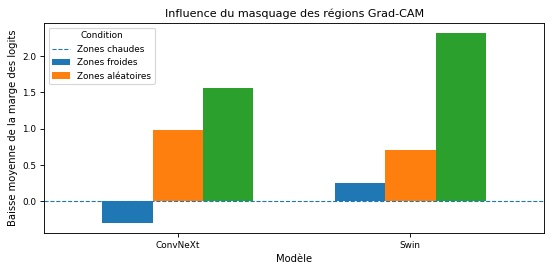

In [27]:

plot_data = (
    results_df
    .groupby(["Modèle", "Condition"])["Baisse de marge"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(
    figsize=(7, 3.5),
    dpi=80
)

plot_data.plot(
    kind="bar",
    ax=ax,
    width=0.65
)

ax.set_title(
    "Influence du masquage des régions Grad-CAM",
    fontsize=10
)

ax.set_xlabel("Modèle", fontsize=9)
ax.set_ylabel(
    "Baisse moyenne de la marge des logits",
    fontsize=9
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.legend(
    title="Condition",
    labels=[
        "Zones chaudes",
        "Zones froides",
        "Zones aléatoires"
    ],
    fontsize=8,
    title_fontsize=8
)

ax.tick_params(axis="both", labelsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
plt.close(fig)
